# Transformation Interpolations:  LSST DP2 <--> SDSS DR18

_Douglas L. Tucker_, _Christina Adair_, _Meagan N.Porter_

_2026.11.13_

## 1. Import Modules

In [1]:
import numpy as np
import pandas as pd

from lsst.daf.butler import Butler
import lsst.geom as geom

import pyvo

import os
import sys
import glob
import math
import datetime
import time
import re
import pickle

from tqdm.notebook import tqdm

from collections import OrderedDict as odict

from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u

import fitsio

from scipy import interpolate
from scipy.optimize import leastsq

import healpy as hp

import plotly
from plotly.offline import download_plotlyjs, plot, iplot
import plotly.graph_objs as go

from IPython.display import Markdown, display

import matplotlib.pyplot as plt

%matplotlib inline

## 2.  Input Parameters

In [2]:
# LSST-->SDSS DR18 (toLSST=False) or SDSS DR18-->LSST (toLSST=True)...
toLSST = True
#toLSST = False

if toLSST:
    # List of LSST bands on which to run the transform fit...
    #bandList = ['g_LSST', 'r_LSST', 'i_LSST', 'z_LSST', 'y_LSST']
    bandList = ['g_LSST', 'r_LSST', 'i_LSST', 'z_LSST', 'gi_LSST']
    # If SDSS-->LSST, then the mag and color to fit against are SDSS...
    # Dictionary of corresponding bands from the other survey...
    matchBand_dict = {'g_LSST':'g_sdss', 'r_LSST':'r_sdss', 'i_LSST':'i_sdss', 'z_LSST':'z_sdss', 'y_LSST':'z_sdss', 'gi_LSST':'gi_sdss'}
    # Color to fit against...
    color_name_1_dict = {'g_LSST':'gi_sdss', 'r_LSST':'gi_sdss', 'i_LSST':'gi_sdss', 'z_LSST':'gi_sdss', 'y_LSST':'gi_sdss', 'gi_LSST':'gi_sdss'}
    # Name of color_name_1 as the label in the QA plots...
    colorLabel_1_dict = {'g_LSST':'$(g-i)_{sdss}$', 'r_LSST':'$(g-i)_{sdss}$', 'i_LSST':'$(g-i)_{sdss}$', 'z_LSST':'$(g-i)_{sdss}$', 'y_LSST':'$(g-i)_{sdss}$', 'gi_LSST':'$(g-i)_{sdss}$'}

else:
    # List of SDSS bands on which to run the transform fit...
    bandList = ['g_sdss', 'r_sdss', 'i_sdss', 'z_sdss','gi_sdss']
    # If LSST-->SDSS, then the mag and color to fit against are LSST...
    # Dictionary of corresponding bands from the other survey...
    matchBand_dict = {'g_sdss':'g_LSST', 'r_sdss':'r_LSST', 'i_sdss':'i_LSST', 'z_sdss':'z_LSST', 'y_sdss':'z_LSST', 'gi_sdss':'gi_LSST'}
    # Color to fit against...
    color_name_1_dict = {'g_sdss':'gi_LSST', 'r_sdss':'gi_LSST', 'i_sdss':'gi_LSST', 'z_sdss':'gi_LSST', 'y_sdss':'gi_LSST', 'gi_sdss':'gi_LSST'}
    # Name of color_name_1 as the label in the QA plots...
    colorLabel_1_dict = {'g_sdss':'$(g-i)_{LSST}$', 'r_sdss':'$(g-i)_{LSST}$', 'i_sdss':'$(g-i)_{LSST}$', 'z_sdss':'$(g-i)_{LSST}$', 'y_sdss':'$(g-i)_{LSST}$', 'gi_sdss':'$(g-i)_{LSST}$'}

# Size of the binsize in color
color_binsize = 0.05

# LSST data
collection = 'LSSTCam/runs/DRP/DP2'

repo = 'dp2_prep'
skymap = 'lsst_cells_v2'
instrument = 'LSSTCam'

# SDSS DR18 TAP service
sdssdr18_tap_url = 'https://mast.stsci.edu/vo-tap/api/v0.1/sdssdr18 - TBD'

# Name of the SDSS cache file (if it exists)
sdss_cache_file = "/home/d/dltucker/rubin-user/DATA/sdss_by_tract_dp2.pkl"

# Use SDSS cache file?
useSDSSCacheFile = False

# Name of the match file
#matchFile = '/home/d/dltucker/DATA/match.lsst_stars_all.w_2025_10.DM-49359a.SDSS_DR18.csv'
#matchFile = '/home/d/dltucker/DATA/match.LSST_stars_all.DP1.SDSS_DR18.csv'
#matchFile = 'match.LSST_COSMOS.DM-51580.SDSS_DR18.csv'
#matchFile = 'match_LSST_DP2_DM_53881_stage3_SDSS_DR18.csv'
matchFile = '/home/d/dltucker/rubin-user/DATA/match_LSST_DP2_SDSS_DR18.csv'

#use match file?
useMatchFile = True

# Name of Aitoff projection PNG plot of the matched file
aitoffPlotFileName = 'match_LSST_DP2_SDSS_DR18.png'

# Base name of fit results output file...
if toLSST:
    resultsFileBaseName = 'transInterp.SDSS_DR18_to_LSST_DP2'
else:
    resultsFileBaseName = 'transInterp.LSST_DP2_to_SDSS_DR18'

# Base name of QA plot output files...
if toLSST:
    qaFileBaseName = 'qaPlot.SDSS_DR18_to_LSST_DP2.interp.fit'
else:
    qaFileBaseName = 'qaPlot.SDSS_DR18_to_LSST_DP2.interp.fit'

# Write a Markdown-formatted summary table of the fits?
write_md_file = True
if write_md_file:
    # Auto-name the .md file based on resultsFileBaseName
    #md_filename = f"{qaFileBaseName}.qa_summary.md"
    md_filename = f"{resultsFileBaseName}.qa_summary.md"

# Verbosity level (0, 1, 2, 3, ...)
verbose = 2




## 3. Define Useful Functions

In [3]:
# Useful class to stop "Run All" at a cell 
#  containing the command "raise StopExecution"
class StopExecution(Exception):
    def _render_traceback_(self):
        pass

In [4]:
# No longer used in this notebook (2026.06.16)
def cross_match_catalogs(df1, df2, ra_name_1, dec_name_1, ra_name_2, dec_name_2):

    # Create SkyCoord objects for both dataframes
    coords1 = SkyCoord(ra=df1[ra_name_1].values*u.degree, 
                       dec=df1[dec_name_1].values*u.degree)

    coords2 = SkyCoord(ra=df2[ra_name_2].values*u.degree, 
                       dec=df2[dec_name_2].values*u.degree)

    # Match coordinates
    max_sep = 3 * u.arcsec  # Maximum separation
    idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

    # Create mask for matches within max_sep
    mask = d2d < max_sep

    # Create a new dataframe with matches
    matches = df1[mask].copy()
    matches['match_idx'] = idx[mask]  # Index of matching object in df2
    matches['separation_arcsec'] = d2d[mask].arcsec  # Separation in arcseconds

    # Add columns from df2 for the matches
    for col in df2.columns:
        matches[f'match_{col}'] = df2.loc[idx[mask], col].values

    # If multiple matches exist for the same source in df1, keep only the closest one
    matches = matches.loc[matches.groupby(matches.index)['separation_arcsec'].idxmin()]

    # If you want to see which objects in df1 had no matches:
    unmatched = df1[~mask]

    return matches, unmatched

In [5]:
# From Zeljko Ivezic:
# Robust estimate of standard deviation: 0.741*(q75-q25)
#  sigmaG = 0.741*(np.percentile(yAux,75)-np.percentile(yAux,25))
# Uncertainty of the median: sqrt(pi/2)*st.dev/sqrt(N)
#  sigGbin[i] = np.sqrt(np.pi/2)*sigmaG/np.sqrt(nPts[i])

def robustStdDev(data):
    sd = 0.741*(np.percentile(data,75)-np.percentile(data,25))
    return sd

def uncMedian(data, npts):
    sd = robustStdDev(data)
    uncMedian = np.sqrt(np.pi/2)*sd/np.sqrt(npts)
    return uncMedian

In [6]:
##################################

def interp1ColorQAPlots1(df, df1, color_name_1, color1_min, color1_max, 
                         title, dmagLabel, outputFileName, verbose):

        
    # Create linear interpolation of the median dmag vs. color bin calculated above...
    response = interpolate.interp1d(df1.index.values.astype(float), df1.bin_median.values, \
                                bounds_error=False, fill_value=0., kind='linear')    

    # Calculate and apply the offset for the individual stars in df, 
    #  based on the linear interpolation calculated above...
    df['offset'] = response(df[color_name_1].values)    
    df['res'] = df['dmag'] - df['offset']    
    if verbose>1:
        print("") 
        print(df[[color_name_1, 'offset', 'res']].head())
        print("")

    # Calculate the 'robust' RMS of the residuals....
    rms = robustStdDev(df['res'].values)


    # Identify range to plot in the dmag (Y-axis) direction...
    dmag_desc = df['dmag'].describe(percentiles=[0.001, 0.999])
    if verbose>1:
        print(dmag_desc)
    dmag_min = math.floor(10*dmag_desc['0.1%'])/10.
    dmag_max = math.ceil(10*dmag_desc['99.9%'])/10.

    dmag_mask = (df['dmag'] >= dmag_min) & (df['dmag'] <= dmag_max)
    df_dmag_mask = df[dmag_mask]
    

    # Identify range to plot in the residuals (Y-axis) direction...
    res_desc = df['res'].describe(percentiles=[0.01, 0.99])
    if verbose>1:
        print("")
        print(res_desc)
        print("") 
    res_min = math.floor(10*res_desc['1%'])/10.
    res_max = math.ceil(10*res_desc['99%'])/10.
    # What the heck; let's just set this to -0.10 mag --> +0.10 mag...
    #res_min = -0.10
    #res_max = +0.10
    res_min = -0.20
    res_max = +0.20


    # For 2d binning below, we mask df for just those stars within 
    #  the res_min, res_max range...
    res_mask = (df['res'] >= res_min) & (df['res'] <= res_max)
    df_res_mask = df[res_mask]
    
    
    # Prepare QA plots...
    #fig = plt.figure(figsize=(40,20))
    fig = plt.figure(figsize=(20,10))
    fig.subplots_adjust(hspace=0.3)
    
    # Modify matplotlib font...
    #font = {'family' : 'normal',
    #        'weight' : 'bold',
    #       'size'   : 22}
    #matplotlib.rc('font', **font)    
    plt.rcParams.update({'font.size': 24})

    
    ## Include a supertitle to the matplotlob figure...
    #fig.suptitle('This is the superTitle')

    
    # Plot 1:  Descriptive text...
    plt.subplot(221)
    plot1Text = """%s \n\n\n\n%s vs. %s\n\n[rms: %.3f] \n\n[%.1f < %s < %.1f]""" % \
                    (title, dmagLabel, colorLabel_1, rms, color1_min, colorLabel_1, color1_max)
    plt.text(0.1,0.00,plot1Text)
    plt.axis('off')

    
    # Plot 2:  2D hexbin histogram of dmag vs. color1...
    plt.subplot(222)
    if len(df_dmag_mask['dmag'].values) < 1000:
        plt.scatter(df_dmag_mask[color_name_1].values, df_dmag_mask['dmag'].values, alpha=0.75, label='Data')
    else:
        # The color of the Data label does not look appropriate; 
        #  so let's just omit it from the legend when doing the hexbin plot
        #hb=plt.hexbin(df_dmag_mask[color_name_1].values, df_dmag_mask['dmag'].values, \
        #                  gridsize=100, bins='log', cmap='inferno', label='Data')
        hb=plt.hexbin(df_dmag_mask[color_name_1].values, df_dmag_mask['dmag'].values, \
                          gridsize=100, bins='log', cmap='inferno')
    ax=plt.axis([color1_min, color1_max, dmag_min, dmag_max])
    plt.xlabel(colorLabel_1)
    plt.ylabel(dmagLabel)
    if len(df_dmag_mask['dmag'].values) >= 1000:
        cb = fig.colorbar(hb)
        cb.set_label('log10(N)')
    plt.grid(color='blue')
    plt.grid(True)
    # Overplot the binned values calculated above:
    plt.errorbar(df1.index.values.astype(float), df1.bin_median.values, yerr=df1.bin_unc.values, 
                 fmt='o', c='lime', label='Bin Median')
    #try:
        #plt.errorbar(df1.index.values.astype(float), df1.bin_median.values, yerr=df1.bin_unc.values, fmt='o')
    #except:
        #plt.errorbar(df1.index.values.astype(float), df1.bin_median.values, fmt='o', markersize=10)
    plt.legend()

    
    # Plot 3:  1d histogram of residuals...
    plt.subplot(223) 
    plt.hist(df_res_mask.loc[:,'res'],bins=100)
    plt.xlabel('residuals [mag]')
    plt.ylabel('Number')
    plt.xlim([res_min, res_max])
    plt.grid(True)
    plt.grid(color='blue')

    
    # Plot 4:  2d hexbin histogram of residuals vs. color1...
    plt.subplot(224) 
    if len(df_dmag_mask['dmag'].values) < 1000:
        plt.scatter(df_res_mask.loc[:, color_name_1].values, df_res_mask.loc[:,'res'].values, alpha=0.75)
    else:
        hb=plt.hexbin(df_res_mask.loc[:, color_name_1].values, df_res_mask.loc[:,'res'].values, \
                      gridsize=100, bins='log', cmap='inferno')
    ax=plt.axis([color1_min, color1_max, res_min, res_max])
    plt.xlabel(colorLabel_1)
    plt.ylabel('Residuals')
    if len(df_dmag_mask['dmag'].values) >= 1000:
        cb = fig.colorbar(hb)
        cb.set_label('log10(N)')
    plt.grid(color='blue')
    plt.grid(True)
    plt.legend()
    
    
    # Plot...
    plt.tight_layout()
    

    # Save QA plots to file...
    plt.savefig(outputFileName)    
    

    return 0


##################################

In [7]:
# Kudos to Copilot ChatGPT-5 for these functions for generating Markdown output 
#  of the fit equations...
# See:  https://copilot.microsoft.com/shares/Nopgin8hutEqEmjqJkteY

def latexify_label(label: str) -> str:
    """Strip $ and convert underscores to LaTeX subscripts."""
    label = label.strip('$')
    return re.sub(r'_(\w+)', r'_{\1}', label)

def latexify_name(name: str) -> str:
    """Convert underscores in names to LaTeX subscripts."""
    return re.sub(r'_(\w+)', r'_{\1}', name)

def make_conversion_str(magName_match, magName):
    """Return a LaTeX conversion string like $g_{LSST} \to g_{DES}$."""
    return f"${latexify_name(magName_match)} \\to {latexify_name(magName)}$"

def make_range_str_interp(color_min, color_max, colorLabel_1):
    """Return a LaTeX range string for the lookup table case."""
    label = latexify_label(colorLabel_1)
    return f"${color_min:.1f} < {label} < {color_max:.1f}$"

## X. Read in Matched Catalog

Only used if `useMatchFile == True` (i.e., to save time not querying LSST DP2/SDSS DR18 and matching the 2 catalogs)...  


In [8]:
## Check to make sure matchFile exists...
if useMatchFile:
    if os.path.isfile(matchFile)==False:
        print("""ERROR:  matchFile %s does not exist...""" % (matchFile))
    if verbose > 0:
        print('matchFile: ', matchFile)


matchFile:  /home/d/dltucker/rubin-user/DATA/match_LSST_DP2_SDSS_DR18.csv


In [9]:
if useMatchFile:
    tab = Table.read(matchFile, format='csv')
    display(tab)

tractId,coord_ra,coord_dec,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,u_cModelFluxErr,u_extendedness,u_psfFlux_flag,g_psfFlux,g_psfFluxErr,g_ap12Flux,g_ap12FluxErr,g_cModelFlux,g_cModelFluxErr,g_extendedness,g_psfFlux_flag,r_psfFlux,r_psfFluxErr,r_ap12Flux,r_ap12FluxErr,r_cModelFlux,r_cModelFluxErr,r_extendedness,r_psfFlux_flag,i_psfFlux,i_psfFluxErr,i_ap12Flux,i_ap12FluxErr,i_cModelFlux,i_cModelFluxErr,i_extendedness,i_psfFlux_flag,z_psfFlux,z_psfFluxErr,z_ap12Flux,z_ap12FluxErr,z_cModelFlux,z_cModelFluxErr,z_extendedness,z_psfFlux_flag,y_psfFlux,y_psfFluxErr,y_ap12Flux,y_ap12FluxErr,y_cModelFlux,y_cModelFluxErr,y_extendedness,y_psfFlux_flag,sdss_index,sdss_sep_arcsec,ra,dec,u,g,r,i,z,u_err,g_err,r_err,i_err,z_err,extinction_u,extinction_g,extinction_r,extinction_i,extinction_z,flags_u,flags_g,flags_r,flags_i,flags_z,mode,clean
int64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,int64,int64
6972,214.58910473250126,-16.293896900882313,6972,0,--,--,--,--,--,--,--,True,64540.188,105.56978,64426.027,139.78456,63996.86,105.474075,0.0,False,87204.82,94.90218,87552.1,132.73032,85963.875,94.067474,0.0,False,96959.1,79.26509,97044.234,114.02842,95879.19,78.98373,0.0,False,--,--,--,--,--,--,--,True,--,--,--,--,--,--,--,True,9597,0.0958969855576142,214.589088088386,-16.293875585026,20.36261,19.37978,19.05654,18.8866,18.87409,0.07022973,0.01608106,0.01713908,0.02065768,0.06059178,0.3485395,0.2715796,0.1878775,0.1396131,0.1038465,275280594176,268468224,4503599895838720,268468224,158604971901440,1,1
6972,214.6023991604071,-16.287340911806496,6972,0,--,--,--,--,--,--,--,True,15976.569,66.10261,16166.585,110.865654,16027.163,66.64881,0.0,False,26492.707,68.90923,26752.258,116.4141,26449.227,69.027245,0.0,False,32721.215,66.57575,33892.574,110.00617,32966.824,67.46956,0.0,False,--,--,--,--,--,--,--,True,--,--,--,--,--,--,--,True,6461,0.0817555262791666,214.602403761815,-16.2873186355743,21.9805,20.88634,20.35164,20.0765,19.78523,0.245817,0.03194631,0.02933295,0.03658684,0.09872143,0.3497347,0.2725109,0.1885218,0.1400919,0.1042026,134250497,275146375168,4503874773745664,275146375168,275280592896,1,1
6972,214.59121793265842,-16.360783066992227,6972,0,--,--,--,--,--,--,--,True,170650.8,138.68587,170731.06,155.01657,168697.52,138.08377,0.0,False,234874.92,133.93301,236126.81,158.7914,231058.03,132.4535,0.0,False,262329.6,116.03646,262606.62,141.97343,258567.94,115.30179,0.0,False,--,--,--,--,--,--,--,True,--,--,--,--,--,--,--,True,11515,0.24180984283682538,214.591207632675,-16.3607166286258,19.34956,18.33256,17.9625,17.83759,17.79373,0.03651699,0.01855082,0.02114729,0.02221755,0.02569637,0.3437463,0.2678448,0.1852938,0.1376932,0.1024184,275280723984,268468240,4503599895838736,268468240,275146506256,1,1
6972,214.59140407131517,-16.359938514368793,6972,0,--,--,--,--,--,--,--,True,80257.74,94.24508,80786.25,127.11301,79953.31,94.48791,0.0,False,110573.47,96.66533,112069.13,136.8999,109939.22,96.41334,0.0,False,123200.055,94.2973,125595.66,132.76349,122330.01,94.2806,0.0,False,--,--,--,--,--,--,--,True,--,--,--,--,--,--,--,True,11516,0.1851702451292352,214.59145737548,-16.359943970865,20.06705,19.14042,18.79998,18.69173,18.69359,0.06725643,0.09391337,0.09546627,0.09584683,0.07648148,0.343726,0.267829,0.1852828,0.137685,0.1024123,268599312,268468240,4503599895838736,268468752,268599312,1,1
6972,214.55962326241675,-16.363146718224552,6972,0,--,--,--,--,--,--,--,True,70675.66,99.0189,70762.59,128.2004,6983

In [10]:
if useMatchFile:
    matches = tab.to_pandas()
    display(matches)

,tractId,coord_ra,coord_dec,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,extinction_r,extinction_i,extinction_z,flags_u,flags_g,flags_r,flags_i,flags_z,mode,clean
0,6972,214.589105,-16.293897,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.187878,0.139613,0.103846,275280594176,268468224,4503599895838720,268468224,158604971901440,1,1
1,6972,214.602399,-16.287341,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.188522,0.140092,0.104203,134250497,275146375168,4503874773745664,275146375168,275280592896,1,1
2,6972,214.591218,-16.360783,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.185294,0.137693,0.102418,275280723984,268468240,4503599895838736,268468240,275146506256,1,1
3,6972,214.591404,-16.359939,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.185283,0.137685,0.102412,268599312,268468240,4503599895838736,268468752,268599312,1,1
4,6972,214.559623,-16.363147,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.187544,0.139365,0.103662,45036271587819536,302022672,4503599929360400,302022672,275179929616,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2247139,11640,7.144526,14.039860,11640,47,NaN,NaN,NaN,NaN,NaN,...,0.196325,0.145891,0.108516,17867466770176,268468224,4503599895838720,285245952,268468224,1,1
2247140,11640,7.237533,14.041711,11640,47,NaN,NaN,NaN,NaN,NaN,...,0.179472,0.133367,0.099200,9007199397380353,275146375168,4503874773745664,268468224,275146375168,1,1
2247141,11640,7.224064,14.054995,11640,47,NaN,NaN,NaN,NaN,NaN,...,0.178253,0.132461,0.098527,9007199388992769,275146342400,4503874773712896,275146342400,275280560128,1,1
2247142,11640,7.160595,14.065834,11640,47,NaN,NaN,NaN,NaN,NaN,...,0.187761,0.139526,0.103782,275146506240,268468224,4503599895969792,268599296,268468224,1,1


## 4. Query LSST Catalog

In [11]:
# ============================================================
# 4. Overlapping tracts + LSST DP2 stars (OPTIMIZED)
# ============================================================

if not useMatchFile:

    # --- 4.1 SDSS DR18 footprint: |Dec| < 15 deg AND |bII| > 15 deg ---
    def tract_overlaps_sdss(tract):
        poly = tract.getOuterSkyPolygon()
        verts = poly.getVertices()

        for v in verts:
            sp = geom.SpherePoint(v)
            ra = sp.getRa().asDegrees()
            dec = sp.getDec().asDegrees()

            if abs(dec) < 15:
                sky = SkyCoord(ra=ra*u.deg, dec=dec*u.deg, frame='icrs')
                if abs(sky.galactic.b.deg) > 15:
                    return True
        return False

    def tracts_overlapping_sdss(skymap):
        return sorted([
            tract.getId()
            for tract in skymap
            if tract_overlaps_sdss(tract)
        ])

    # --- 4.2 Build initial tract list from geometry only ---
    skybutler = Butler(repo, collections=collection, skymap=skymap)
    skymap_obj = skybutler.get("skyMap", skymap="lsst_cells_v2")

    geom_tract_list = tracts_overlapping_sdss(skymap_obj)
    if verbose > 2:
        print("Geometric SDSS-overlap tracts:", geom_tract_list)

    # --- 4.3 Helper: tract vertices in RA/Dec ---
    def tract_vertices(tractId):
        tract = skymap_obj.generateTract(tractId)
        verts = tract.getVertexList()
        return [(v.getRa().asDegrees(), v.getDec().asDegrees()) for v in verts]

    # --- 4.4 Query LSST DP2 only where data exist ---
    butler = Butler(repo, collections=collection)
    INCOLS = ["coord_ra", "coord_dec", "tract", "patch"]
    for band in "ugrizy":
        INCOLS += [
            f"{band}_psfFlux", f"{band}_psfFluxErr",
            f"{band}_ap12Flux", f"{band}_ap12FluxErr",
            f"{band}_cModelFlux", f"{band}_cModelFluxErr",
            f"{band}_extendedness", f"{band}_psfFlux_flag"
        ]

    LSST_stars_list = []
    tracts_with_rubin = []

    #for tractId in geom_tract_list:
    #    print(f"Processing LSST tract {tractId},")
    # tqdm progress bar
    for tractId in tqdm(geom_tract_list, desc="Processing LSST tracts"):
        try:
            raw = butler.get(
                "object",
                dataId={"skymap": "lsst_cells_v2", "tract": tractId},
                collections=[collection],
                parameters={"columns": INCOLS}
            ).to_pandas()
        except Exception as e:
            if verbose > 2:  print(f"  No DP2 object table for tract {tractId}: {e}")
            continue

        raw.insert(0, "tractId", tractId)

        # SNR + flag cuts
        sel = (raw["r_psfFlux"] / raw["r_psfFluxErr"] > 5)
        for b in ["g", "r", "i"]:
            sel &= (raw[f"{b}_psfFlux_flag"] == 0)

        LSST = raw[sel]

        # Star selection
        stars = LSST[(LSST["g_extendedness"] < 0.5) &
                     (LSST["r_extendedness"] < 0.5)]

        if verbose > 2:  print(f"  Stars: {len(stars)}")
        if len(stars) == 0:
            continue

        LSST_stars_list.append(stars)
        tracts_with_rubin.append(tractId)

    # --- 4.5 Final LSST star catalog + tract list ---
    if len(LSST_stars_list) == 0:
        raise RuntimeError("No LSST stars found in any overlapping tract.")

    LSST_stars_all = pd.concat(LSST_stars_list, ignore_index=True)
    tract_list = sorted(set(tracts_with_rubin))

    print(f"\nTotal LSST stars: {len(LSST_stars_all)}")
    print("Tracts with BOTH SDSS footprint overlap AND Rubin DP2 data:")
    print(tract_list)

    # --- 4.6 table_patches only for tracts with Rubin data ---
    table_patches = pd.DataFrame({
        "tractId": tract_list,
        "vertices_deg": [tract_vertices(t) for t in tract_list]
    })


In [12]:
if not useMatchFile:
    display(LSST_stars_all)

## 5. Query SDSS DR18 Catalog

In [13]:
# ============================================================
# 5. Query SDSS DR18 (OPTIMIZED + CACHED + PANDAS QA FILTERS)
# ============================================================

if not useMatchFile:

    # ------------------------------------------------------------
    # WARNING:  astroquery caches downloads to ~/.astropy/cache.
    #           Be sure to "rm -rf ~/.astropy/cache after running
    #           astroquery queries resulting in large downloads.
    # ------------------------------------------------------------

    from astroquery.sdss import SDSS

    # ------------------------------------------------------------
    # 5.0 SDSS QA mask function (pandas implementation)
    # ------------------------------------------------------------
    def clean_sdss_photometry(df):
        """DR18-compatible SDSS photometric quality cuts."""

        PSF_MEAS = 0x10000000

        # Require PSF measurements in g,r,i (u,z optional)
        psf_meas = (
            ((df.flags_g & PSF_MEAS) != 0) &
            ((df.flags_r & PSF_MEAS) != 0) &
            ((df.flags_i & PSF_MEAS) != 0)
        )

        # Primary detection
        primary = (df.mode != 0)
        print()

        # SDSS clean flag (already includes many QA checks)
        clean_phot = (df.clean == 1)

        # Reasonable magnitude errors
        good_err = (
            (df.g_err < 0.2) &
            (df.r_err < 0.2) &
            (df.i_err < 0.2)
        )

        # u-band special handling (looser)
        u_ok = (df.u_err < 0.5)

        #mask = psf_meas & primary & clean_phot & good_err & u_ok
        mask = psf_meas & clean_phot & good_err & u_ok
        return df[mask].reset_index(drop=True)


    # ------------------------------------------------------------
    # 5.1 Helper: tract bounding box
    # ------------------------------------------------------------
    def tract_bounding_box(vertices):
        ras = np.array([v[0] for v in vertices])
        decs = np.array([v[1] for v in vertices])
        ras_wrapped = np.unwrap(np.deg2rad(ras))
        ras_deg = np.rad2deg(ras_wrapped)
        return ras_deg.min(), ras_deg.max(), decs.min(), decs.max()


    # ------------------------------------------------------------
    # 5.2 SDSS query (lightweight RA/Dec window only)
    # ------------------------------------------------------------
    def query_sdss_dr18_box(ra_min, ra_max, dec_min, dec_max, max_retries=5):

        query = f"""
            SELECT s.ra, s.dec,
                s.psfMag_u AS u, s.psfMag_g AS g, s.psfMag_r AS r,
                s.psfMag_i AS i, s.psfMag_z AS z,
                s.psfMagErr_u as u_err, s.psfMagErr_g as g_err, s.psfMagErr_r as r_err,
                s.psfMagErr_i as i_err, s.psfMagErr_z as z_err,
                s.extinction_u, s.extinction_g, s.extinction_r,
                s.extinction_i, s.extinction_z,
                s.flags_u, s.flags_g, s.flags_r, s.flags_i, s.flags_z,
                s.mode, s.clean
            FROM Star s
            WHERE s.ra BETWEEN {ra_min} AND {ra_max}
              AND s.dec BETWEEN {dec_min} AND {dec_max}
        """

        for attempt in range(max_retries):
            try:
                result = SDSS.query_sql(
                    query,
                    data_release=18,
                    timeout=120,
                    url="https://skyserver.sdss.org/dr18/SkyServerWS/SearchTools/SqlSearch"
                )
                if result is None:
                    return None
                return result.to_pandas()
            except Exception as e:
                print(f"  SDSS query failed ({attempt+1}/{max_retries}): {e}")
                time.sleep(2 + 2*attempt)

        print("  SDSS query failed after all retries.")
        return None


    # ------------------------------------------------------------
    # 5.3 Load from cache or query SDSS
    # ------------------------------------------------------------
    if useSDSSCacheFile and os.path.isfile(sdss_cache_file):
        print(f"Loading SDSS results from cache: {sdss_cache_file}")
        with open(sdss_cache_file, "rb") as f:
            sdss_by_tract = pickle.load(f)

    else:
        sdss_by_tract = {}

        for tractId, vertices in zip(table_patches["tractId"],
                                     table_patches["vertices_deg"]):

            print(f"\n=== SDSS query for tract {tractId} ===")
            ra_min, ra_max, dec_min, dec_max = tract_bounding_box(vertices)
            print(f"  RA [{ra_min:.3f}, {ra_max:.3f}], Dec [{dec_min:.3f}, {dec_max:.3f}]")

            sdss_df = query_sdss_dr18_box(ra_min, ra_max, dec_min, dec_max)

            if sdss_df is None or len(sdss_df) == 0:
                print("  No SDSS sources.")
                continue

            # Skip malformed tables
            if not {"ra", "dec"}.issubset(sdss_df.columns):
                print("  SDSS returned malformed table — skipping.")
                continue

            print(f"  Retrieved {len(sdss_df)} SDSS sources")

            # Apply SDSS QA cuts in pandas
            sdss_clean = clean_sdss_photometry(sdss_df)
            print(f"  After SDSS QA cuts: {len(sdss_clean)} sources")

            if len(sdss_clean) == 0:
                print("  No clean SDSS sources after QA cuts.")
                continue

            sdss_by_tract[tractId] = sdss_clean.copy()

        print("\nSDSS DR18 querying complete.")
        print(f"Saving SDSS results to cache: {sdss_cache_file}")
        with open(sdss_cache_file, "wb") as f:
            pickle.dump(sdss_by_tract, f)

    print(f"\nNumber of tracts with SDSS data: {len(sdss_by_tract)}")


In [14]:
#print(sdss_df)
#print(sdss_clean)

## 6. Match LSST and SDSS DR18 stars

In [15]:
# ============================================================
# 6. Cross‑match LSST DP2 ↔ SDSS DR18 (OPTIMIZED)
# ============================================================

if not useMatchFile:
    
    def crossmatch_rubin_sdss(rubin_df, sdss_df, max_sep_arcsec=1.0):
        
        import astropy.units as u
        from astropy.coordinates import SkyCoord
        
        rubin_coords = SkyCoord(
            rubin_df["coord_ra"].astype(float).values * u.deg,
            rubin_df["coord_dec"].astype(float).values * u.deg
        )
        sdss_coords = SkyCoord(
            sdss_df["ra"].astype(float).values * u.deg,
            sdss_df["dec"].astype(float).values * u.deg
        )
        idx, sep2d, _ = rubin_coords.match_to_catalog_sky(sdss_coords)
        mask = sep2d < (max_sep_arcsec * u.arcsec)

        matched_rubin = rubin_df[mask].copy()
        matched_rubin["sdss_index"] = idx[mask]
        matched_rubin["sdss_sep_arcsec"] = sep2d[mask].arcsec

        matched_sdss = sdss_df.iloc[idx[mask]].reset_index(drop=True)
        return matched_rubin.reset_index(drop=True), matched_sdss

    matched_rows = []

    for tractId, sdss_df in sdss_by_tract.items():
        rubin_df = LSST_stars_all[LSST_stars_all["tractId"] == tractId]

        if len(rubin_df) == 0:
            continue

        print(f"\nMatching tract {tractId}: Rubin {len(rubin_df)}, SDSS {len(sdss_df)}")

        #m_rubin, m_sdss = crossmatch_rubin_sdss(rubin_df, sdss_df)
        # Skip malformed SDSS tables
        required_cols = {"ra", "dec"}
        if not required_cols.issubset(sdss_df.columns):
            print(f"  Skipping tract {tractId}: SDSS table missing RA/Dec columns")
            continue

        m_rubin, m_sdss = crossmatch_rubin_sdss(rubin_df, sdss_df)


        print(f"  Matched {len(m_rubin)} objects")
        if len(m_rubin) > 0:
            merged = pd.concat(
                [m_rubin.reset_index(drop=True),
                 m_sdss.reset_index(drop=True)],
                axis=1
            )
            matched_rows.append(merged)

    if len(matched_rows) == 0:
        raise RuntimeError("No Rubin–SDSS matches found in any tract.")

    matches = pd.concat(matched_rows, ignore_index=True)
    print(f"\nTotal matched objects: {len(matches)}")


In [16]:
if not useMatchFile:
    display(matches)

In [17]:
# Save new match file...
if not useMatchFile:
    matches.to_csv(matchFile,index=False)

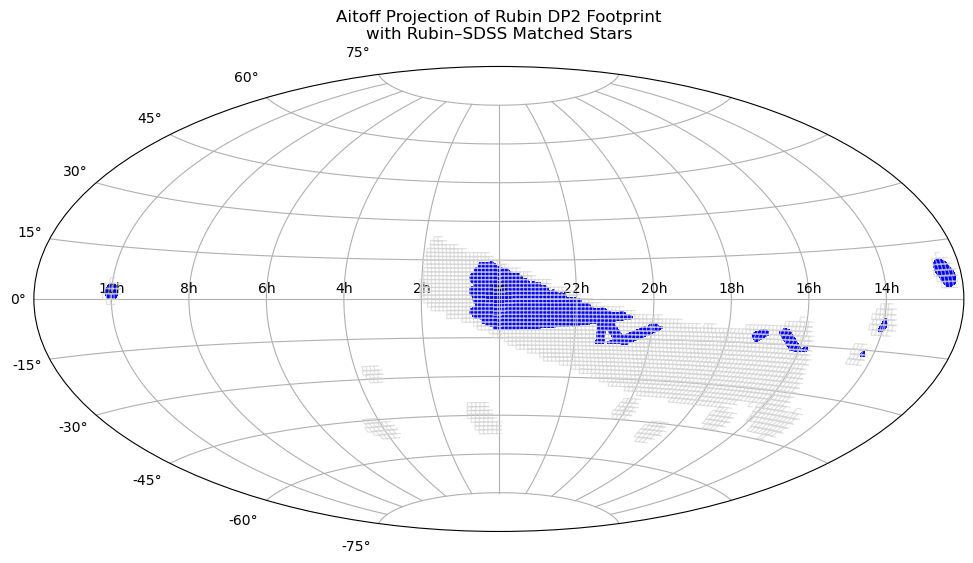

In [18]:
# Plot Aitoff sky plot of new match file...

#if not useMatchFile:
if True:
    
    # ------------------------------------------------------------
    # Extract RA/Dec from your final matches table
    # ------------------------------------------------------------
    ra = matches["coord_ra"].values
    dec = matches["coord_dec"].values

    # Convert RA to [-180, +180] degrees
    ra_wrapped = np.remainder(ra + 180.0, 360.0) - 180.0

    # Convert to radians
    ra_rad = np.deg2rad(-ra_wrapped)
    dec_rad = np.deg2rad(dec)

    # ------------------------------------------------------------
    # Self-contained: find ONLY the tracts that contain DP2 data
    # ------------------------------------------------------------
    _but = Butler(repo, collections=collection)

    # Query all object-table datasets in the DP2 collection
    refs = list(_but.registry.queryDatasets(
        "object",
        collections=[collection],
        findFirst=True
    ))

    # Extract unique tract IDs
    dp2_tracts = sorted({ref.dataId["tract"] for ref in refs})

    # Load skymap
    _skymap = _but.get("skyMap", skymap="lsst_cells_v2")

    # Convert tract polygons to RA/Dec
    def _tract_vertices_deg(tract):
        poly = tract.getOuterSkyPolygon()
        verts = poly.getVertices()
        ra_list, dec_list = [], []
        for v in verts:
            sp = geom.SpherePoint(v)
            ra_list.append(sp.getRa().asDegrees())
            dec_list.append(sp.getDec().asDegrees())
        return list(zip(ra_list, dec_list))

    # Build list of polygons for DP2 tracts only
    _dp2_vertices = [_tract_vertices_deg(_skymap[tid]) for tid in dp2_tracts]

    # ------------------------------------------------------------
    # Create Aitoff projection
    # ------------------------------------------------------------
    plt.figure(figsize=(12, 7))
    ax = plt.subplot(111, projection="aitoff")

    # ------------------------------------------------------------
    # 1. Plot ONLY Rubin DP2 tracts (not full skymap)
    # ------------------------------------------------------------
    for vertices in _dp2_vertices:
        ra_poly = np.array([v[0] for v in vertices])
        dec_poly = np.array([v[1] for v in vertices])

        # Wrap RA to [-180, +180]
        ra_poly_wrapped = np.remainder(ra_poly + 180.0, 360.0) - 180.0

        # Convert to radians
        ra_poly_rad = np.deg2rad(-ra_poly_wrapped)
        dec_poly_rad = np.deg2rad(dec_poly)

        ax.plot(ra_poly_rad, dec_poly_rad,
                color="lightgray", linewidth=0.8, alpha=0.7)

    # ------------------------------------------------------------
    # 2. Plot matched stars on top
    # ------------------------------------------------------------
    ax.scatter(ra_rad, dec_rad, s=1, alpha=0.5, color="blue")
    #ax.set_xticklabels(['14h','16h','18h','20h','22h','0h','2h','4h','6h','8h','10h'])
    ax.set_xticklabels(['10h','8h','6h','4h','2h','0h','22h','20h','18h','16h','14h'])

    ax.grid(True)
    plt.title("Aitoff Projection of Rubin DP2 Footprint\nwith Rubin–SDSS Matched Stars", pad=20)

    # Save to PNG file
    plt.savefig(aitoffPlotFileName, dpi=200, bbox_inches="tight")

    # Plot to screen
    plt.show()


##  7. Add ABmag Columns to Matched Catalog Data Frame

In [19]:
# Copy matches to df...
df = matches.copy()

In [20]:
# Define common parameters
flux_bands = ['u', 'g', 'r', 'i', 'z', 'y']
offset = 31.4 # For magnitude calculation
sentinel_value = -9999.0

# Loop through each band to calculate both magnitude and magnitude error
for band in flux_bands:
    
    flux_col = f'{band}_psfFlux'
    flux_err_col = f'{band}_psfFluxErr'
    mag_col = f'{band}_psfMag'
    mag_err_col = f'{band}_psfMagErr'

    # Condition for valid flux (must be positive for log10 and division)
    valid_flux_condition = df[flux_col] > 0

    # Calculate magnitude
    df[mag_col] = np.where(valid_flux_condition,
                           -2.5 * np.log10(df[flux_col]) + offset,
                           sentinel_value)

    # Calculate magnitude error
    df[mag_err_col] = np.where(valid_flux_condition,
                               1.086 * df[flux_err_col] / df[flux_col],
                               sentinel_value)



/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/co

In [21]:
df

,tractId,coord_ra,coord_dec,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,g_psfMag,g_psfMagErr,r_psfMag,r_psfMagErr,i_psfMag,i_psfMagErr,z_psfMag,z_psfMagErr,y_psfMag,y_psfMagErr
0,6972,214.589105,-16.293897,6972,0,NaN,NaN,NaN,NaN,NaN,...,19.375424,0.001776,19.048649,0.001182,18.933529,0.000888,-9999.000000,-9999.000000,-9999.0,-9999.0
1,6972,214.602399,-16.287341,6972,0,NaN,NaN,NaN,NaN,NaN,...,20.891291,0.004493,20.342184,0.002825,20.112926,0.002210,-9999.000000,-9999.000000,-9999.0,-9999.0
2,6972,214.591218,-16.360783,6972,0,NaN,NaN,NaN,NaN,NaN,...,18.319729,0.000883,17.972908,0.000619,17.852882,0.000480,-9999.000000,-9999.000000,-9999.0,-9999.0
3,6972,214.591404,-16.359939,6972,0,NaN,NaN,NaN,NaN,NaN,...,19.138783,0.001275,18.790873,0.000949,18.673473,0.000831,-9999.000000,-9999.000000,-9999.0,-9999.0
4,6972,214.559623,-16.363147,6972,0,NaN,NaN,NaN,NaN,NaN,...,19.276825,0.001522,18.421156,0.000908,18.087610,0.000656,-9999.000000,-9999.000000,-9999.0,-9999.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2247139,11640,7.144526,14.039860,11640,47,NaN,NaN,NaN,NaN,NaN,...,18.400935,0.002340,17.011986,0.001242,16.080477,0.000876,15.645408,0.000855,-9999.0,-9999.0
2247140,11640,7.237533,14.041711,11640,47,NaN,NaN,NaN,NaN,NaN,...,20.968455,0.012312,19.616313,0.005902,18.962777,0.005483,18.630766,0.004322,-9999.0,-9999.0
2247141,11640,7.224064,14.054995,11640,47,NaN,NaN,NaN,NaN,NaN,...,22.120249,0.032022,21.271290,0.022091,20.901029,0.028456,20.769020,0.027476,-9999.0,-9999.0
2247142,11640,7.160595,14.065834,11640,47,NaN,NaN,NaN,NaN,NaN,...,17.357093,0.001373,16.797984,0.001120,16.585275,0.001135,16.499908,0.001323,-9999.0,-9999.0


In [22]:
df.columns

Index(['tractId', 'coord_ra', 'coord_dec', 'tract', 'patch', 'u_psfFlux',
       'u_psfFluxErr', 'u_ap12Flux', 'u_ap12FluxErr', 'u_cModelFlux',
       'u_cModelFluxErr', 'u_extendedness', 'u_psfFlux_flag', 'g_psfFlux',
       'g_psfFluxErr', 'g_ap12Flux', 'g_ap12FluxErr', 'g_cModelFlux',
       'g_cModelFluxErr', 'g_extendedness', 'g_psfFlux_flag', 'r_psfFlux',
       'r_psfFluxErr', 'r_ap12Flux', 'r_ap12FluxErr', 'r_cModelFlux',
       'r_cModelFluxErr', 'r_extendedness', 'r_psfFlux_flag', 'i_psfFlux',
       'i_psfFluxErr', 'i_ap12Flux', 'i_ap12FluxErr', 'i_cModelFlux',
       'i_cModelFluxErr', 'i_extendedness', 'i_psfFlux_flag', 'z_psfFlux',
       'z_psfFluxErr', 'z_ap12Flux', 'z_ap12FluxErr', 'z_cModelFlux',
       'z_cModelFluxErr', 'z_extendedness', 'z_psfFlux_flag', 'y_psfFlux',
       'y_psfFluxErr', 'y_ap12Flux', 'y_ap12FluxErr', 'y_cModelFlux',
       'y_cModelFluxErr', 'y_extendedness', 'y_psfFlux_flag', 'sdss_index',
       'sdss_sep_arcsec', 'ra', 'dec', 'u', 'g', 'r', '

In [23]:
# Rename columns...
df.rename(columns={'coord_ra':'RA_LSST',
                   'coord_dec':'DEC_LSST',
                   'u_psfMag':'u_LSST',
                   'g_psfMag':'g_LSST',
                   'r_psfMag':'r_LSST',
                   'i_psfMag':'i_LSST',
                   'z_psfMag':'z_LSST',
                   'y_psfMag':'y_LSST',
                   'u_psfMagErr':'u_err_LSST',
                   'g_psfMagErr':'g_err_LSST',
                   'r_psfMagErr':'r_err_LSST',
                   'i_psfMagErr':'i_err_LSST',
                   'z_psfMagErr':'z_err_LSST',
                   'y_psfMagErr':'y_err_LSST',
                   'u':'u_sdss',
                   'g':'g_sdss',
                   'r':'r_sdss',
                   'i':'i_sdss',
                   'z':'z_sdss',
                   'u_err':'u_err_sdss',
                   'g_err':'g_err_sdss',
                   'r_err':'r_err_sdss',
                   'i_err':'i_err_sdss',
                   'z_err':'z_err_sdss',
                   'flags_u':'u_flags_sdss',
                   'flags_g':'g_flags_sdss',
                   'flags_r':'r_flags_sdss',
                   'flags_i':'i_flags_sdss',
                   'flags_z':'z_flags_sdss',
                   'mode':'mode_sdss',
                   'clean':'clean_sdss'
                 },inplace=True)

df.head(5)


,tractId,RA_LSST,DEC_LSST,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,g_LSST,g_err_LSST,r_LSST,r_err_LSST,i_LSST,i_err_LSST,z_LSST,z_err_LSST,y_LSST,y_err_LSST
0,6972,214.589105,-16.293897,6972,0,NaN,NaN,NaN,NaN,NaN,...,19.375424,0.001776,19.048649,0.001182,18.933529,0.000888,-9999.0,-9999.0,-9999.0,-9999.0
1,6972,214.602399,-16.287341,6972,0,NaN,NaN,NaN,NaN,NaN,...,20.891291,0.004493,20.342184,0.002825,20.112926,0.002210,-9999.0,-9999.0,-9999.0,-9999.0
2,6972,214.591218,-16.360783,6972,0,NaN,NaN,NaN,NaN,NaN,...,18.319729,0.000883,17.972908,0.000619,17.852882,0.000480,-9999.0,-9999.0,-9999.0,-9999.0
3,6972,214.591404,-16.359939,6972,0,NaN,NaN,NaN,NaN,NaN,...,19.138783,0.001275,18.790873,0.000949,18.673473,0.000831,-9999.0,-9999.0,-9999.0,-9999.0
4,6972,214.559623,-16.363147,6972,0,NaN,NaN,NaN,NaN,NaN,...,19.276825,0.001522,18.421156,0.000908,18.087610,0.000656,-9999.0,-9999.0,-9999.0,-9999.0


In [24]:
df.columns

Index(['tractId', 'RA_LSST', 'DEC_LSST', 'tract', 'patch', 'u_psfFlux',
       'u_psfFluxErr', 'u_ap12Flux', 'u_ap12FluxErr', 'u_cModelFlux',
       'u_cModelFluxErr', 'u_extendedness', 'u_psfFlux_flag', 'g_psfFlux',
       'g_psfFluxErr', 'g_ap12Flux', 'g_ap12FluxErr', 'g_cModelFlux',
       'g_cModelFluxErr', 'g_extendedness', 'g_psfFlux_flag', 'r_psfFlux',
       'r_psfFluxErr', 'r_ap12Flux', 'r_ap12FluxErr', 'r_cModelFlux',
       'r_cModelFluxErr', 'r_extendedness', 'r_psfFlux_flag', 'i_psfFlux',
       'i_psfFluxErr', 'i_ap12Flux', 'i_ap12FluxErr', 'i_cModelFlux',
       'i_cModelFluxErr', 'i_extendedness', 'i_psfFlux_flag', 'z_psfFlux',
       'z_psfFluxErr', 'z_ap12Flux', 'z_ap12FluxErr', 'z_cModelFlux',
       'z_cModelFluxErr', 'z_extendedness', 'z_psfFlux_flag', 'y_psfFlux',
       'y_psfFluxErr', 'y_ap12Flux', 'y_ap12FluxErr', 'y_cModelFlux',
       'y_cModelFluxErr', 'y_extendedness', 'y_psfFlux_flag', 'sdss_index',
       'sdss_sep_arcsec', 'ra', 'dec', 'u_sdss', 'g_sdss'

## 8. Add Color Columns to Matched Catalog Data Frame

In [25]:
# Add color columns...
df.loc[:,'ug_LSST'] = df.loc[:,'u_LSST'] - df.loc[:,'g_LSST']
df.loc[:,'gr_LSST'] = df.loc[:,'g_LSST'] - df.loc[:,'r_LSST']
df.loc[:,'ri_LSST'] = df.loc[:,'r_LSST'] - df.loc[:,'i_LSST']
df.loc[:,'iz_LSST'] = df.loc[:,'i_LSST'] - df.loc[:,'z_LSST']
df.loc[:,'zy_LSST'] = df.loc[:,'z_LSST'] - df.loc[:,'y_LSST']
df.loc[:,'gi_LSST'] = df.loc[:,'g_LSST'] - df.loc[:,'i_LSST']

df.loc[:,'ug_sdss'] = df.loc[:,'u_sdss'] - df.loc[:,'g_sdss']
df.loc[:,'gr_sdss'] = df.loc[:,'g_sdss'] - df.loc[:,'r_sdss']
df.loc[:,'ri_sdss'] = df.loc[:,'r_sdss'] - df.loc[:,'i_sdss']
df.loc[:,'iz_sdss'] = df.loc[:,'i_sdss'] - df.loc[:,'z_sdss']
df.loc[:,'gi_sdss'] = df.loc[:,'g_sdss'] - df.loc[:,'i_sdss']


In [26]:
# Insert dmag column...
df.loc[:,'dmag'] = -9999.

## 9. Create Initial Mask

In [27]:
mask1 = (df["g_LSST"] > 16.5) & (df["g_LSST"] < 30.)
mask2 = (df["r_LSST"] > 16.5) & (df["r_LSST"] < 30.)
mask3 = (df["i_LSST"] > 16.5) & (df["i_LSST"] < 30.)
mask4 = (df["z_LSST"] > 16.5) & (df["z_LSST"] < 30.)
mask5 = (df["y_LSST"] > 16.0) & (df["y_LSST"] < 30.)
mask6 = df["g_err_LSST"] <= 0.05
mask7 = df["r_err_LSST"] <= 0.05
mask8 = df["i_err_LSST"] <= 0.05
mask9 = df["z_err_LSST"] <= 0.05
mask10 = df["y_err_LSST"] <= 0.10
mask_LSST = mask1 & mask2 & mask3 & mask4 & mask5 & mask6 & mask7 & mask8 & mask9 & mask10

mask1 = (df["u_sdss"] > 15.) & (df["u_sdss"] < 30.)
mask2 = (df["g_sdss"] > 15.) & (df["g_sdss"] < 30.)
mask3 = (df["r_sdss"] > 15.) & (df["r_sdss"] < 30.)
mask4 = (df["i_sdss"] > 15.) & (df["i_sdss"] < 30.)
mask5 = (df["z_sdss"] > 15.) & (df["z_sdss"] < 30.)
mask6 = df["u_err_sdss"] <= 0.10
mask7 = df["g_err_sdss"] <= 0.05
mask8 = df["r_err_sdss"] <= 0.05
mask9 = df["i_err_sdss"] <= 0.05
mask10 = df["z_err_sdss"] <= 0.10
mask_sdss = mask1 & mask2 & mask3 & mask4 & mask5 & mask6 & mask7 & mask8 & mask9 & mask10

mask = mask_LSST & mask_sdss


In [28]:
df

,tractId,RA_LSST,DEC_LSST,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,ri_LSST,iz_LSST,zy_LSST,gi_LSST,ug_sdss,gr_sdss,ri_sdss,iz_sdss,gi_sdss,dmag
0,6972,214.589105,-16.293897,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.115120,10017.933529,0.000000,0.441896,0.98283,0.32324,0.16994,0.01251,0.49318,-9999.0
1,6972,214.602399,-16.287341,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.229258,10019.112926,0.000000,0.778365,1.09416,0.53470,0.27514,0.29127,0.80984,-9999.0
2,6972,214.591218,-16.360783,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.120027,10016.852882,0.000000,0.466847,1.01700,0.37006,0.12491,0.04386,0.49497,-9999.0
3,6972,214.591404,-16.359939,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.117400,10017.673473,0.000000,0.465310,0.92663,0.34044,0.10825,-0.00186,0.44869,-9999.0
4,6972,214.559623,-16.363147,6972,0,NaN,NaN,NaN,NaN,NaN,...,0.333546,10017.087610,0.000000,1.189215,2.24815,0.89972,0.31488,0.18739,1.21460,-9999.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2247139,11640,7.144526,14.039860,11640,47,NaN,NaN,NaN,NaN,NaN,...,0.931509,0.435069,10014.645408,2.320458,2.75884,1.52542,0.91356,0.54103,2.43898,-9999.0
2247140,11640,7.237533,14.041711,11640,47,NaN,NaN,NaN,NaN,NaN,...,0.653536,0.332011,10017.630766,2.005678,1.83099,1.45544,0.66657,0.41563,2.12201,-9999.0
2247141,11640,7.224064,14.054995,11640,47,NaN,NaN,NaN,NaN,NaN,...,0.370261,0.132009,10019.769020,1.219220,0.96044,0.67128,0.53317,0.31967,1.20445,-9999.0
2247142,11640,7.160595,14.065834,11640,47,NaN,NaN,NaN,NaN,NaN,...,0.212708,0.085368,10015.499908,0.771818,1.19890,0.59726,0.22632,0.15587,0.82358,-9999.0


## 10. Make Backup Copies of Initial Mask and Original Data Frame

In [29]:
# Make a backup copy of original df...
df_orig = df.copy()

# Make a backup copy of original mask...
mask_orig = mask.copy()

## 11. Generate Lookup Table in Each Filter Band




# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 
g_LSST
# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 


count    552436.000000
mean          0.783043
std           0.295308
min          -0.946670
1%            0.134781
50%           0.749130
99%           1.601502
max           2.766430
Name: gi_sdss, dtype: float64
0.1 1.7

[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9  0.95 1.   1.05 1.1  1.15 1.2  1.25 1.3  1.35 1.4  1.45
 1.5  1.55 1.6  1.65 1.7 ]
[0.125 0.175 0.225 0.275 0.325 0.375 0.425 0.475 0.525 0.575 0.625 0.675
 0.725 0.775 0.825 0.875 0.925 0.975 1.025 1.075 1.125 1.175 1.225 1.275
 1.325 1.375 1.425 1.475 1.525 1.575 1.625 1.675]

      gi_sdss bin_interval bin_label
1568  0.57056  (0.55, 0.6]     0.575
1573  1.15329  (1.15, 1.2]     1.175
1580  0.82124  (0.8, 0.85]     0.825
1582  0.62449  (0.6, 0.65]     0.625
1588  0.74906  (0.7, 0.75]     0.725


          bin_interva

/tmp/ipykernel_1147/2942279713.py:84: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grp = df.groupby(['bin_label'])



count    552436.000000
mean          0.000384
std           0.077766
min          -1.751032
1%           -0.121218
50%          -0.000052
99%           0.114237
max           6.105925
Name: res, dtype: float64



/tmp/ipykernel_1147/2670721698.py:135: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()





# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 
r_LSST
# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 


count    552436.000000
mean          0.783043
std           0.295308
min          -0.946670
1%            0.134781
50%           0.749130
99%           1.601502
max           2.766430
Name: gi_sdss, dtype: float64
0.1 1.7

[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9  0.95 1.   1.05 1.1  1.15 1.2  1.25 1.3  1.35 1.4  1.45
 1.5  1.55 1.6  1.65 1.7 ]
[0.125 0.175 0.225 0.275 0.325 0.375 0.425 0.475 0.525 0.575 0.625 0.675
 0.725 0.775 0.825 0.875 0.925 0.975 1.025 1.075 1.125 1.175 1.225 1.275
 1.325 1.375 1.425 1.475 1.525 1.575 1.625 1.675]

      gi_sdss bin_interval bin_label
1568  0.57056  (0.55, 0.6]     0.575
1573  1.15329  (1.15, 1.2]     1.175
1580  0.82124  (0.8, 0.85]     0.825
1582  0.62449  (0.6, 0.65]     0.625
1588  0.74906  (0.7, 0.75]     0.725


          bin_interva

/tmp/ipykernel_1147/2942279713.py:84: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grp = df.groupby(['bin_label'])


... (11 outputs left out)

/tmp/ipykernel_1147/2942279713.py:84: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grp = df.groupby(['bin_label'])



count    552436.000000
mean         -0.001490
std           0.073387
min          -8.615719
1%           -0.120432
50%          -0.000169
99%           0.105982
max           3.492610
Name: res, dtype: float64



/tmp/ipykernel_1147/2670721698.py:135: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


| Conversion                |   RMS | Applicable Color Range     | QA Plot                                                                            | Lookup Table                                                               |
|:--------------------------|------:|:---------------------------|:-----------------------------------------------------------------------------------|:---------------------------------------------------------------------------|
| $g_{sdss} \to g_{LSST}$   | 0.02  | $0.1 < (g-i)_{sdss} < 1.7$ | [link](_static/plots/qaPlot_transInterp.SDSS_DR18_to_LSST_DP2.g_LSST_gi_sdss.png)  | [link](_static/data/transInterp.SDSS_DR18_to_LSST_DP2.g_LSST_gi_sdss.csv)  |
| $r_{sdss} \to r_{LSST}$   | 0.019 | $0.1 < (g-i)_{sdss} < 1.7$ | [link](_static/plots/qaPlot_transInterp.SDSS_DR18_to_LSST_DP2.r_LSST_gi_sdss.png)  | [link](_static/data/transInterp.SDSS_DR18_to_LSST_DP2.r_LSST_gi_sdss.csv)  |
| $i_{sdss} \to i_{LSST}$   | 0.02  | $0.1 < (g-i)_{sdss} < 1.7$ | [link](_static/pl

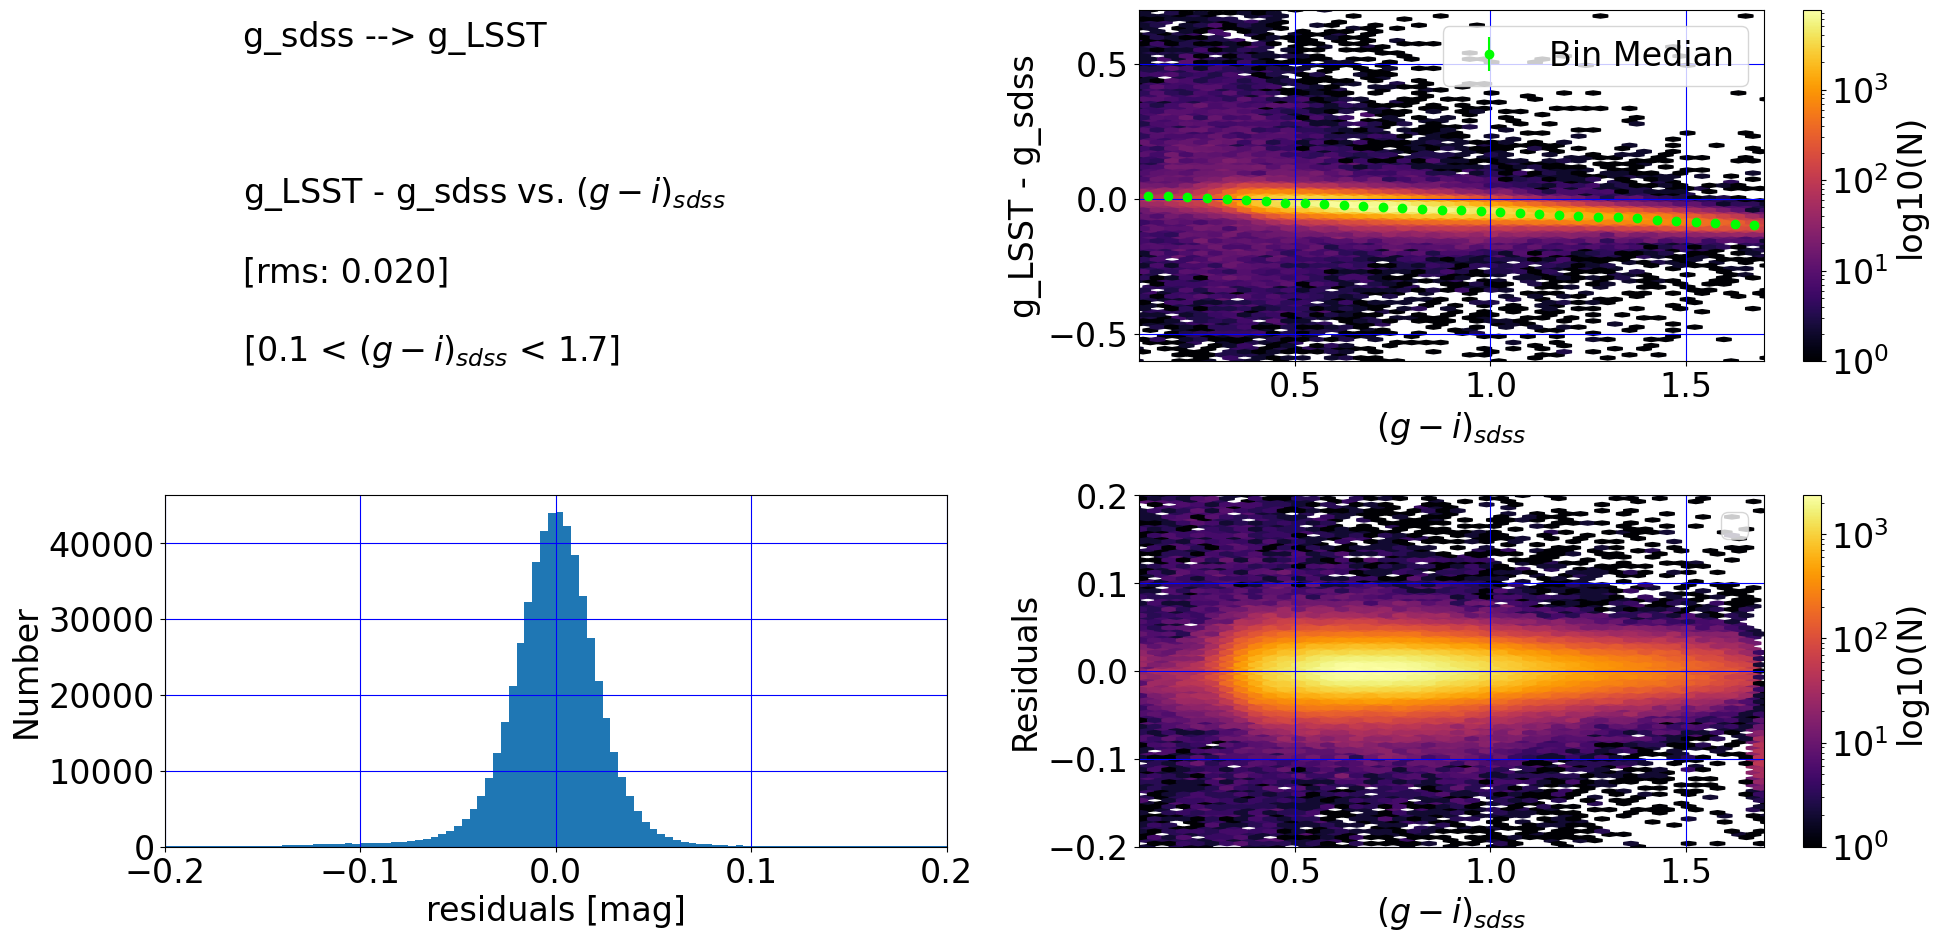

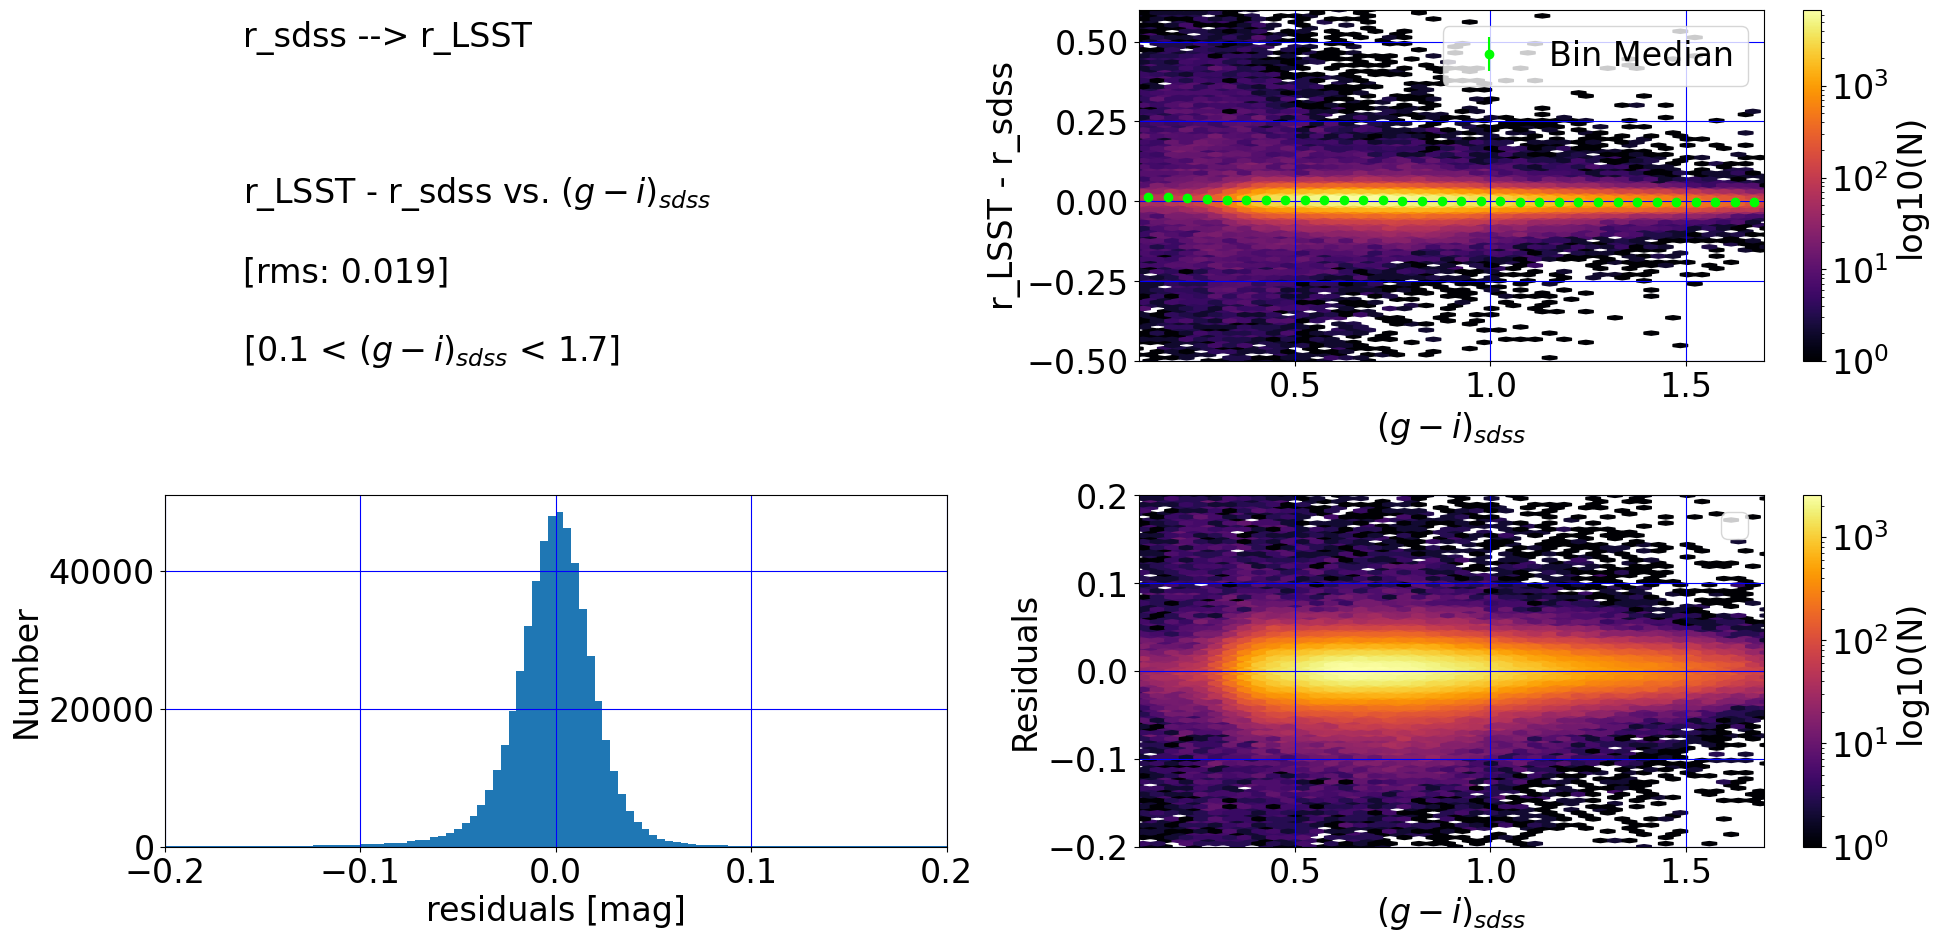

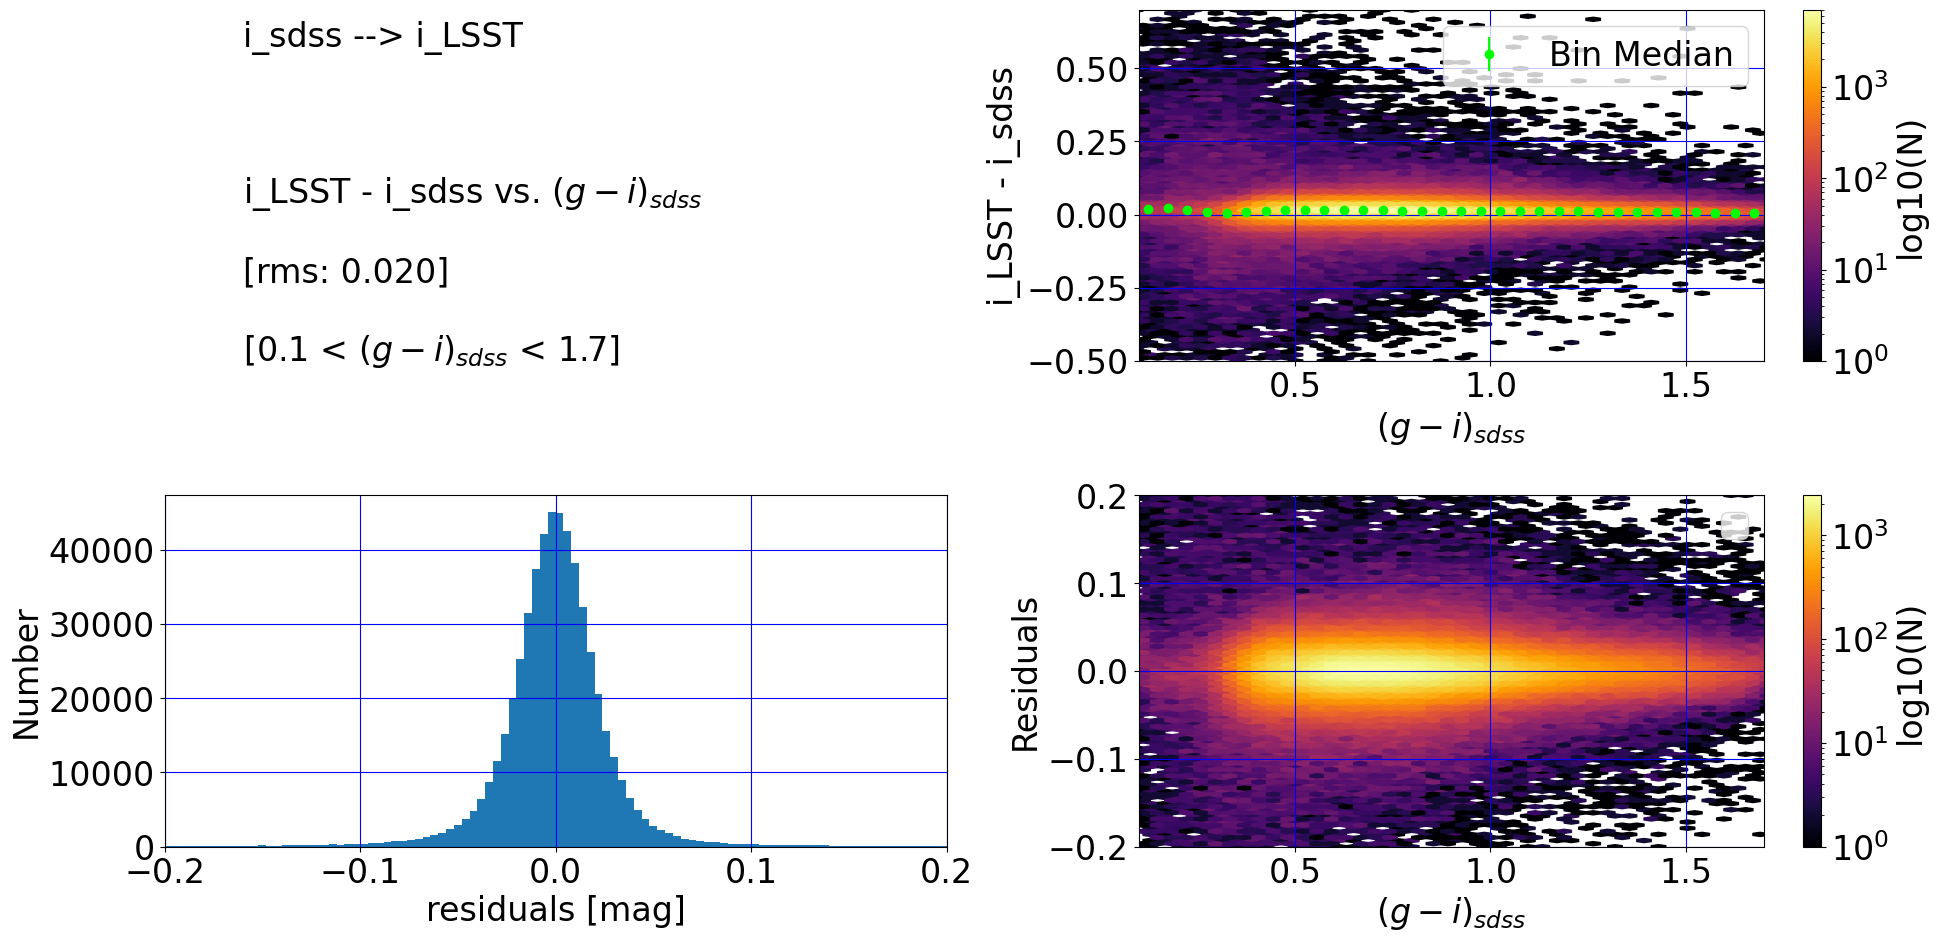

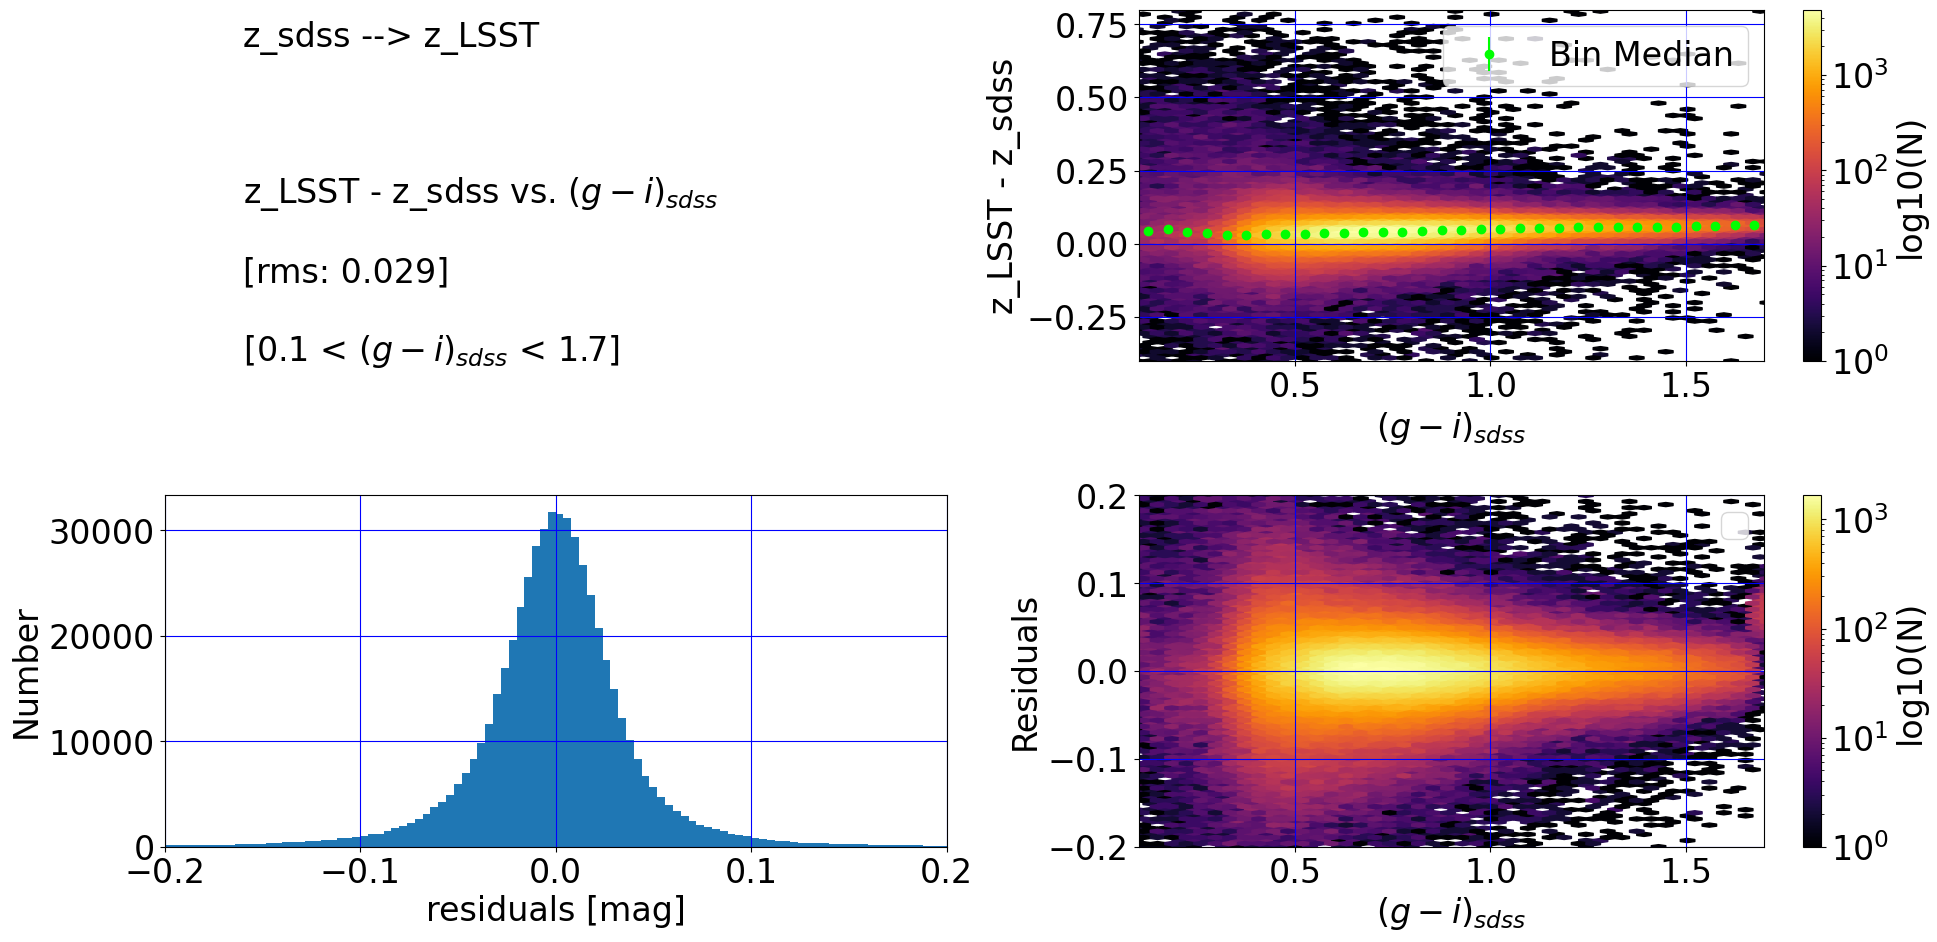

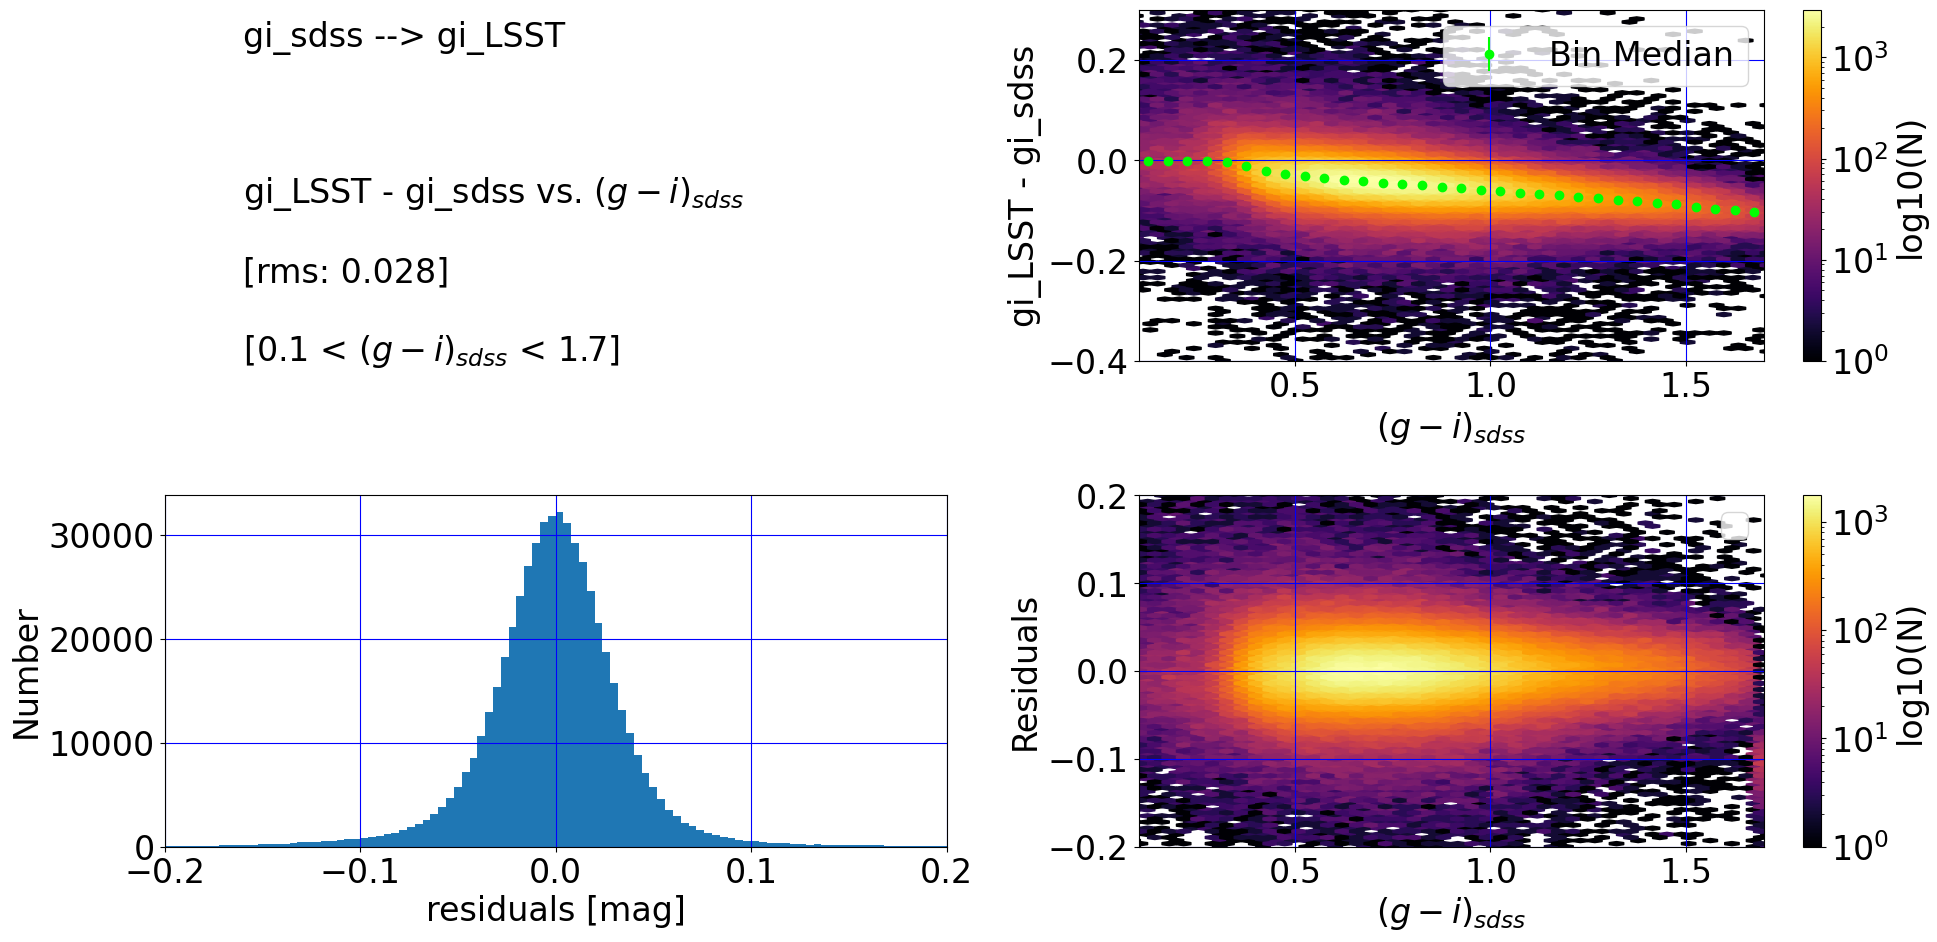

In [30]:
# --- Accumulator for ALL bands ---
qa_rows_all = []

# --- Main loop ---
for band in bandList:
    
    print("")
    print("")
    print("") 
    print("# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # ")
    print(band)
    print("# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # ")
    print("")
    
    magName = band
    magName_match = matchBand_dict[band]
    color_name_1 = color_name_1_dict[band]
    colorLabel_1 = colorLabel_1_dict[band]

    
    # Grab the original version of df from the backup copy...
    df = df_orig.copy()

    # Grab the original version of mask from the backup copy...
    mask = mask_orig.copy()

    # Update dmag column...
    df.loc[:,'dmag'] = df.loc[:,magName] - df.loc[:,magName_match]

    # Update mask...
    mask1 = abs(df['dmag']) <= 10.
    mask2 = ( ( df[color_name_1] > -3. ) & ( df[color_name_1] < 6.0 ) )
    mask = mask & mask1 & mask2

    # make a copy of original df, overwriting the old one...
    df = df[mask].copy()

    # Identify dmag and color1 series...
    dmag =  df.loc[:,'dmag']
    color1 = df.loc[:,color_name_1]


    # Calculate the color range to bin and the number of bins, 
    #  based on the 0.01%-99.99% color range...
    #color1_desc = df[color_name_1].describe(percentiles=[0.0001, 0.9999])
    #color1_min = math.floor(10*color1_desc['0.01%'])/10.
    #color1_max = math.ceil(10*color1_desc['99.99%'])/10.
    color1_desc = df[color_name_1].describe(percentiles=[0.01, 0.99])
    color1_min = math.floor(10*color1_desc['1%'])/10.
    color1_max = math.ceil(10*color1_desc['99%'])/10.
    if verbose>1:
        print("")
        print(color1_desc)
        print(color1_min, color1_max)
        print("")
    binsize = color_binsize
    ranges = np.arange(color1_min,color1_max+binsize,binsize)
    # Label the bins by their mid-point...
    labels = np.arange(color1_min,color1_max,binsize) + 0.5*binsize
    
    #nbins = int((color1_max-color1_min)/binsize)+1
    #ranges = np.linspace(color1_min, color1_max, nbins+1)
    ## Label the bins by their mid-point...
    #labels = np.linspace(color1_min, color1_max-binsize, nbins) + 0.5*binsize

    #nbins = math.floor((color1_max-color1_min)/binsize) + 1
    #ranges = np.linspace(color1_min, color1_max, nbins)
    ## Label the bins by their mid-point...
    #labels = np.linspace(color1_min, color1_max-binsize, nbins-1) + 0.5*binsize
    
    if verbose:
        print(ranges)
        print(labels)
    
    # Bin the data, adding "bin_interval" and "bin_label' to the df dataframe...
    df['bin_interval'] = pd.cut(df[color_name_1], bins=ranges, precision=0)
    df['bin_label'] = pd.cut(df[color_name_1], bins=ranges, labels=labels)
    if verbose>1:
        print("")
        print(df[[color_name_1,'bin_interval','bin_label']].head())
        print("")

    # Perform pandas grouping/aggregating functions on sigma-clipped Data Frame...
    df_grp = df.groupby(['bin_label'])
    bin_interval = df_grp['bin_interval'].first()
    dmag_num = df_grp['dmag'].count()
    dmag_mean = df_grp['dmag'].mean()
    dmag_sd = df_grp['dmag'].std()
    dmag_err = dmag_sd/np.sqrt(dmag_num-1)
    dmag_median = df_grp['dmag'].median()
    dmag_rsd = df_grp['dmag'].apply(robustStdDev)
    dmag_unc = np.sqrt(np.pi/2)*dmag_rsd/np.sqrt(dmag_num)
    #dmag_rsd = dmag_sd
    #dmag_unc = dmag_err

    # Rename some of the pandas series...
    dmag_num.name    = 'bin_num'
    dmag_mean.name   = 'bin_mean'
    dmag_sd.name     = 'bin_stddev'
    dmag_err.name    = 'bin_stderr'
    dmag_median.name = 'bin_median'
    dmag_rsd.name    = 'bin_rstddev'
    dmag_unc.name    = 'bin_unc'
    
    # Create new data frame containing all the relevant aggregate quantities...
    df1 = pd.concat( [bin_interval, dmag_num, \
                      dmag_mean, dmag_sd, dmag_err, \
                      dmag_median, dmag_rsd, dmag_unc, ], \
                    join='outer', axis=1 )
    
    if verbose>1:
        print("")
        print(df1)
        print("")
    
    
    # Create results output file...
    resultsFile = """%s.%s_%s.csv""" % (resultsFileBaseName, band, color_name_1)
    df1.to_csv(resultsFile)
    if verbose>1:
        print("""Writing binned values to %s""" % (resultsFile))

    
    # Create name for QA plot output file...
    outputFileName = """qaPlot_%s.%s_%s.png""" % (resultsFileBaseName, band, color_name_1)

    # Create title and labels for use in QA plots...
    title = """%s --> %s""" % (magName_match, magName)
    dmagLabel = """%s - %s""" % (magName, magName_match)


    # Create QA plots...
    status = interp1ColorQAPlots1(df, df1, color_name_1, color1_min, color1_max, 
                                     title, dmagLabel, outputFileName, verbose)

    # Calculate the 'robust' RMS of the residuals....
    #rms_val = df1['bin_rstddev'].median()  # or mean, or df1['bin_unc'].median()
    rms_val = robustStdDev(df['res'].values)
    rms_val = round(rms_val, 3)

    conversion_str = make_conversion_str(magName_match, magName)
    range_str = make_range_str_interp(color1_min, color1_max, colorLabel_1)

    qa_rows_all.append({
        "Conversion": conversion_str,
        "RMS": rms_val,
        "Applicable Color Range": range_str,
        "QA Plot": f"[link](_static/plots/{outputFileName})",
        "Lookup Table": f"[link](_static/data/{resultsFile})"
    })


# --- After ALL bands processed: display one big table ---
if qa_rows_all:
    qa_df_all = pd.DataFrame(qa_rows_all)
    md_table_str = qa_df_all.to_markdown(index=False)
    md_table_str = md_table_str.replace(r'\_', '_')
    print(md_table_str)

    if write_md_file:
        with open(md_filename, "w") as f:
            f.write(md_table_str)
        print(f"\nMarkdown table written to: {md_filename}")
  